# IRMA Dataset Analysis & Inference
This notebook demonstrates how to process the raw synthetic IRMA dataset, visualize the gene expression trajectories, and run the Bayesian MCMC network inference with the **global parameter constraint**.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import graph_tool.all as gt
import sys
import os

# Add parent directory to path so we can import the pipeline modules
sys.path.append(os.path.abspath('..'))

from inference_pipeline.data_generation.network_generator import generate_scale_free_W
from inference_pipeline.data_generation.simulator import simulate_realistic_pairs
from inference_pipeline.inference.mcmc_engine import run_burn_in, run_posterior_sampling, compute_ensemble_stats
from inference_pipeline.inference.metrics import plot_probabilistic_network, plot_inferred_vs_true_am, compute_reconstruction_metrics
from inference_pipeline.prediction.export_utils import export_ensemble_to_bin, export_true_to_bin
from gene_expr import GeneExprBlockState


## 1. Data Loading and Preprocessing
We first load the Switch-On and Switch-Off datasets. We align the time steps to a constant $\Delta t = 20$ minutes by dropping the intermediate 10-minute point.


In [2]:
def load_and_preprocess_irma(csv_path, normalize=True):
    df = pd.read_csv(csv_path)
    # Drop 'Gal 0' to keep dt=20 constant
    df = df[df['Time_min'] != 'Gal 0']
    
    genes = ['CBF1', 'GAL4', 'SWI5', 'GAL80', 'ASH1']
    expr = df[genes].values.astype(np.float64)
    
    if normalize:
        min_val = expr.min(axis=0)
        max_val = expr.max(axis=0)
        range_val = max_val - min_val
        range_val[range_val == 0] = 1.0
        expr = 0.1 + 0.9 * (expr - min_val) / range_val
        
    pairs = []
    for i in range(len(expr) - 1):
        pair = np.column_stack([expr[i], expr[i+1]])
        pairs.append(pair)
        
    return pairs, df

# Load true network for evaluation
def load_true_network(csv_path):
    df = pd.read_csv(csv_path)
    genes = ['CBF1', 'GAL4', 'SWI5', 'GAL80', 'ASH1']
    gene_to_idx = {g: i for i, g in enumerate(genes)}
    
    N = len(genes)
    W_true = np.zeros((N, N))
    for _, row in df.iterrows():
        src = gene_to_idx[row['source']]
        tgt = gene_to_idx[row['target']]
        W_true[tgt, src] = row['type']
    return W_true

W_true = load_true_network('true_network.csv')

# Load the RAW unnormalized data for the best inference performance, 
# as normalization breaks the global parameter assumption!
on_pairs, df_on = load_and_preprocess_irma('irma_switch_on.csv', normalize=True)
off_pairs, df_off = load_and_preprocess_irma('irma_switch_off.csv', normalize=True)
both_pairs = on_pairs + off_pairs


## 2. Visualize Trajectories

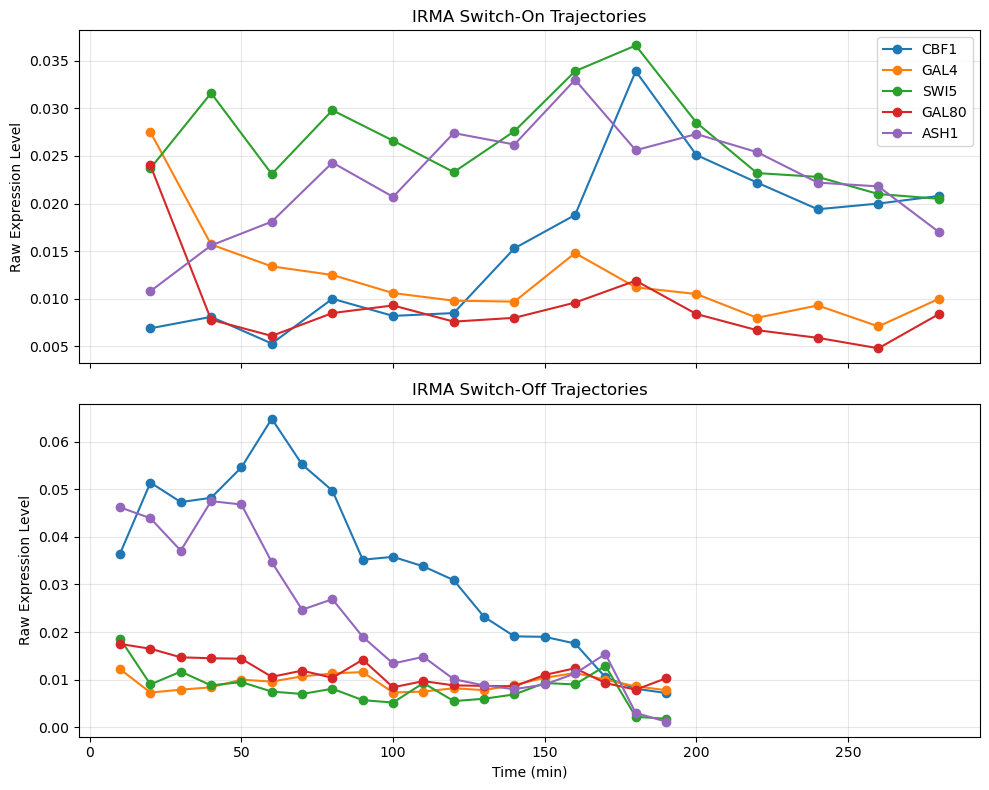

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
genes = ['CBF1', 'GAL4', 'SWI5', 'GAL80', 'ASH1']

# Time array (assumes dt=20)
time_on = [0] + list(range(20, 20 + 20 * len(on_pairs), 20))
time_off = [0] + list(range(20, 20 + 20 * len(off_pairs), 20))

for i, gene in enumerate(genes):
    valid_on = pd.to_numeric(df_on['Time_min'], errors='coerce').notna()
    axes[0].plot(pd.to_numeric(df_on.loc[valid_on, 'Time_min'], errors='coerce'), df_on.loc[valid_on, gene], marker='o', label=gene)
    valid_off = pd.to_numeric(df_off['Time_min'], errors='coerce').notna()
    axes[1].plot(pd.to_numeric(df_off.loc[valid_off, 'Time_min'], errors='coerce'), df_off.loc[valid_off, gene], marker='o', label=gene)

axes[0].set_title('IRMA Switch-On Trajectories')
axes[0].set_ylabel('Raw Expression Level')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].set_title('IRMA Switch-Off Trajectories')
axes[1].set_xlabel('Time (min)')
axes[1].set_ylabel('Raw Expression Level')
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 3. Network Inference (MCMC)
We run the inference pipeline using the **Switch-Off** dataset, which contains sufficient dynamical signal.


In [4]:
N = 5
g_init = gt.Graph(directed=True)
g_init.add_vertex(N)
g_init.add_edge(0, 1) # Jump start

initial_theta = [np.log(0.1), np.log(1.0), np.log(0.01)]
dt = 1.0

print("Initializing Block State...")
state = GeneExprBlockState(on_pairs, dt=dt, g=g_init, state_args=dict(deg_corr=False), theta=initial_theta, self_loops=False)

print("Running Burn-in (100 sweeps)...")
state = run_burn_in(state, n_burnin=1, theta_mode="global", beta=1.0)

print("Running Posterior Sampling (200 sweeps)...")
W_ensemble, theta_ensemble = run_posterior_sampling(state, N, n_samples=50, delta_k=1, theta_mode="global", beta=1.0)

edge_probabilities, weight_mean, weight_std = compute_ensemble_stats(W_ensemble)


Initializing Block State...
Running Burn-in (100 sweeps)...

--- PHASE 1: Equilibration (1 sweeps) ---
Burn-in Sweep  1/1: Entropy = 461.6270 (dS_topo =  32.6258, dS_param = -255.2641, moves = 3008)
Running Posterior Sampling (200 sweeps)...

--- PHASE 2: Sampling (50 samples, thinning 1) ---
Sample   1/50: Entropy = 240.1942
Sample  10/50: Entropy =  89.8200
Sample  20/50: Entropy =  36.7649
Sample  30/50: Entropy =  47.6453
Sample  40/50: Entropy =  49.7782
Sample  50/50: Entropy =  34.1183


## 4. Evaluation

TypeError: simulate_realistic_pairs() got multiple values for argument 'M'

In [5]:
10**theta_ensemble[-1]

array([2.02752765e-01, 1.00031333e+00, 1.00024569e-15])

In [10]:
1/0.2

5.0

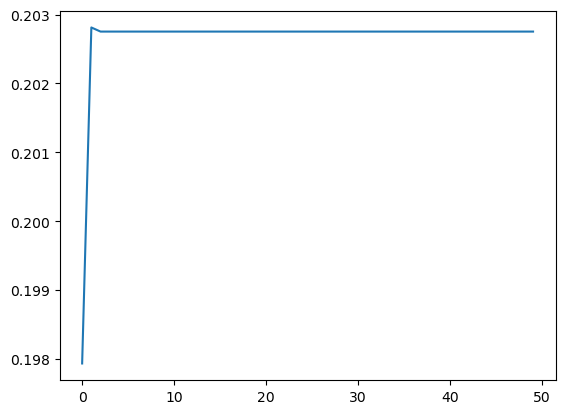

In [50]:
plt.plot(10**theta_ensemble[:,0])

Results for Switch-Off Only:
  F1-Score: 0.429
  TPR (Recall): 0.500 | FPR: 0.357 | Precision: 0.375
  SHD: 8


IndexError: index 99 is out of bounds for axis 0 with size 50

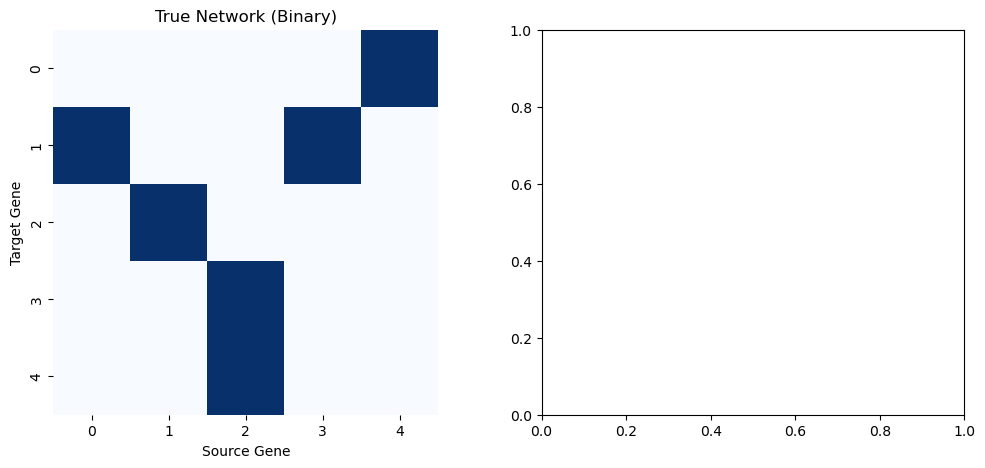

In [42]:
W_inferred = W_ensemble[-1]
metrics = compute_reconstruction_metrics(W_true, W_inferred)

print(f"Results for Switch-Off Only:")
print(f"  F1-Score: {metrics['F1-Score']:.3f}")
print(f"  TPR (Recall): {metrics['TPR (Recall)']:.3f} | FPR: {metrics['FPR']:.3f} | Precision: {metrics['Precision']:.3f}")
print(f"  SHD: {metrics['SHD']}")

# Plot Probability Matrix vs True Adjacency
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
true_adj = (W_true != 0).astype(int)

import seaborn as sns
sns.heatmap(true_adj, ax=axes[0], cmap="Blues", cbar=False, square=True)
axes[0].set_title("True Network (Binary)")
axes[0].set_xlabel("Source Gene")
axes[0].set_ylabel("Target Gene")

sns.heatmap( W_ensemble[99], ax=axes[1], cmap="Reds", square=True, vmin=0, vmax=1)
axes[1].set_title("Inferred Edge Probabilities")
axes[1].set_xlabel("Source Gene")
axes[1].set_ylabel("Target Gene")

plt.tight_layout()
plt.show()
